# **Mapping Residential Development Trajectories as Indicators of Emerging and Future Business Markets**

Week 3

•	Feature Engineering:

- Growth
- Acceleration
- Persistence
- Development Intensity

•	EDA – Exploratory Data Analysis


In [ ]:
import pandas as pd

# Loading bps_msa_units_monthly data
df_units = pd.read_csv('bps_msa_units_monthly.csv')
print("\n Overview of bps_msa_units_monthly.csv")
print("Head:")
print(df_units.head())
print("\nInfo:")
df_units.info()

# Loading bps_msa_value_monthly data
df_value = pd.read_csv('bps_msa_value_monthly.csv')
print("\nOverview of bps_msa_value_monthly.csv")
print("Head:")
print(df_value.head())
print("\nInfo:")
df_value.info()


 Overview of bps_msa_units_monthly.csv
Head:
     CSA     CBSA                                               Name  Total  \
0  999.0  10180.0  Abilene, TX                                   ...   29.0   
1  184.0  10420.0  Akron, OH                                     ...   38.0   
2  999.0  10500.0  Albany, GA                                    ...   13.0   
3  440.0  10540.0  Albany-Lebanon, OR                            ...   18.0   
4  104.0  10580.0  Albany-Schenectady-Troy, NY                   ...  107.0   

   1 Unit  2 Units  3 and 4 Units  5 Units or More  \
0    29.0      0.0            0.0              0.0   
1    38.0      0.0            0.0              0.0   
2    13.0      0.0            0.0              0.0   
3    13.0      0.0            0.0              5.0   
4    59.0      2.0            6.0             40.0   

   Num of Structures With 5 Units or More  year  month        date  
0                                     0.0  2020      1  2020-01-01  
1               

## **Merging Units and Value Datasets**

In [ ]:
import pandas as pd

# Standardizing 'date' columns
df_units['date'] = pd.to_datetime(df_units['date'])
df_value['date'] = pd.to_datetime(df_value['date'])

# Renaming 'Total' columns to distinguish them after melting
df_units_processed = df_units.rename(columns={'Total': 'Total_Units'})
df_value_processed = df_value.rename(columns={'Total': 'Total_Value'})

# Defining common identifier columns and measure columns for melting
id_vars_common = ['CSA', 'CBSA', 'Name', 'year', 'month', 'date']
residential_structure_type_cols = ['1 Unit', '2 Units', '3 and 4 Units', '5 Units or More']

# Melting df_units_processed to long format
df_units_long = pd.melt(df_units_processed,
                        id_vars=id_vars_common + ['Total_Units', 'Num of Structures With 5 Units or More'],
                        value_vars=residential_structure_type_cols,
                        var_name='residential_structure_type',
                        value_name='units_count')

# Melting df_value_processed to long format
df_value_long = pd.melt(df_value_processed,
                        id_vars=id_vars_common + ['Total_Value'],
                        value_vars=residential_structure_type_cols,
                        var_name='residential_structure_type',
                        value_name='value_usd')

# Merging the two long format dataframes
df_merged = pd.merge(df_units_long,
                     df_value_long,
                     on=id_vars_common + ['residential_structure_type'],
                     how='inner')

print("Head of the merged and long-format DataFrame:")
print(df_merged.head())
print("\nInfo of the merged and long-format DataFrame:")
df_merged.info()


Head of the merged and long-format DataFrame:
     CSA     CBSA                                               Name  year  \
0  999.0  10180.0  Abilene, TX                                   ...  2020   
1  184.0  10420.0  Akron, OH                                     ...  2020   
2  999.0  10500.0  Albany, GA                                    ...  2020   
3  440.0  10540.0  Albany-Lebanon, OR                            ...  2020   
4  104.0  10580.0  Albany-Schenectady-Troy, NY                   ...  2020   

   month       date  Total_Units  Num of Structures With 5 Units or More  \
0      1 2020-01-01         29.0                                     0.0   
1      1 2020-01-01         38.0                                     0.0   
2      1 2020-01-01         13.0                                     0.0   
3      1 2020-01-01         18.0                                     1.0   
4      1 2020-01-01        107.0                                     3.0   

  residential_structure_type

In [ ]:
# Subsetting to maintain only relevant variables for the analysis
df_merged = df_merged[['CSA', 'CBSA', 'Name', 'year', 'month', 'date', 'residential_structure_type', 'units_count', 'value_usd']]
df_merged

,CSA,CBSA,Name,year,month,date,residential_structure_type,units_count,value_usd
0,999.0,10180.0,"Abilene, TX ...",2020,1,2020-01-01,1 Unit,29.0,5942
1,184.0,10420.0,"Akron, OH ...",2020,1,2020-01-01,1 Unit,38.0,19128
2,999.0,10500.0,"Albany, GA ...",2020,1,2020-01-01,1 Unit,13.0,1540
3,440.0,10540.0,"Albany-Lebanon, OR ...",2020,1,2020-01-01,1 Unit,13.0,3649
4,104.0,10580.0,"Albany-Schenectady-Troy, NY ...",2020,1,2020-01-01,1 Unit,59.0,16195
...,...,...,...,...,...,...,...,...,...
186399,276.0,49620.0,"York-Hanover, PA ...",2026,7,2026-07-01,5 Units or More,0.0,0
186400,566.0,49660.0,"Youngstown-Warren, OH ...",2026,7,2026-07-01,5 Units or More,0.0,0
186401,472.0,49700.0,"Yuba City, CA ...",2026,7,2026-07-01,5 Units or More,0.0,0
186402,999.0,49740.0,"Yuma, AZ ...",2026,7,2026-07-01,5 Units or More,32.0,2938


In [ ]:
# Checking for missing entries
df_merged.isnull().sum()

,0
CSA,0
CBSA,0
Name,0
year,0
month,0
date,0
residential_structure_type,0
units_count,0
value_usd,0


## **Feature Engineering**

In [ ]:
# Extracting State from 'Name' column
df_merged['State'] = df_merged['Name'].apply(lambda x: x.split(',')[-1].strip() if pd.notna(x) and ',' in x else None)

# Sorting the DataFrame by relevant identifiers and date for time-series calculations
df_merged = df_merged.sort_values(by=['CSA', 'CBSA', 'Name', 'residential_structure_type', 'date'])

# Grouping keys for time-series calculations
group_cols = ['CSA', 'CBSA', 'Name', 'residential_structure_type']

# 1. Growth (Monthly and Yearly Percentage Change)
# Units growth
df_merged['units_growth_1m'] = df_merged.groupby(group_cols)['units_count'].pct_change(periods=1)
df_merged['units_growth_12m'] = df_merged.groupby(group_cols)['units_count'].pct_change(periods=12)

# Value growth
df_merged['value_growth_1m'] = df_merged.groupby(group_cols)['value_usd'].pct_change(periods=1)
df_merged['value_growth_12m'] = df_merged.groupby(group_cols)['value_usd'].pct_change(periods=12)

# 2. Acceleration (Rate of change of growth)
df_merged['units_acceleration_1m'] = df_merged.groupby(group_cols)['units_growth_1m'].diff(periods=1)
df_merged['value_acceleration_1m'] = df_merged.groupby(group_cols)['value_growth_1m'].diff(periods=1)

# 3. Persistence (Rolling Standard Deviation as an inverse measure of persistence)
# A lower rolling std might indicate more persistent (less volatile) development.
df_merged['units_rolling_std_3m'] = df_merged.groupby(group_cols)['units_count'].rolling(window=3, min_periods=1).std().reset_index(level=group_cols, drop=True)
df_merged['value_rolling_std_3m'] = df_merged.groupby(group_cols)['value_usd'].rolling(window=3, min_periods=1).std().reset_index(level=group_cols, drop=True)

# 4. Development Intensity (Value per Unit)
# Handling potential division by zero by replacing 0 units with NaN before division
df_merged['development_intensity'] = df_merged['value_usd'] / df_merged['units_count'].replace(0, pd.NA)

# Dataframe Overview
print("\nHead of the DataFrame with new features:")
print(df_merged.head())

# Data Structure Overview
print("\nInfo of the DataFrame with new features:")
df_merged.info()


Head of the DataFrame with new features:
         CSA     CBSA                                               Name  \
18050  101.0  10180.0  Abilene, TX                                   ...   
18971  101.0  10180.0  Abilene, TX                                   ...   
19892  101.0  10180.0  Abilene, TX                                   ...   
20813  101.0  10180.0  Abilene, TX                                   ...   
21734  101.0  10180.0  Abilene, TX                                   ...   

       year  month       date residential_structure_type  units_count  \
18050  2024      1 2024-01-01                     1 Unit         28.0   
18971  2024      2 2024-02-01                     1 Unit         31.0   
19892  2024      3 2024-03-01                     1 Unit         18.0   
20813  2024      4 2024-04-01                     1 Unit         43.0   
21734  2024      5 2024-05-01                     1 Unit         33.0   

       value_usd State  units_growth_1m  units_growth_12m  val

In [ ]:
# Saving merged dataset to .csv
df_merged.to_csv('bps_msa_units_value_merged_dataset.csv', index=False)

# **Exploratory Data Analysis**

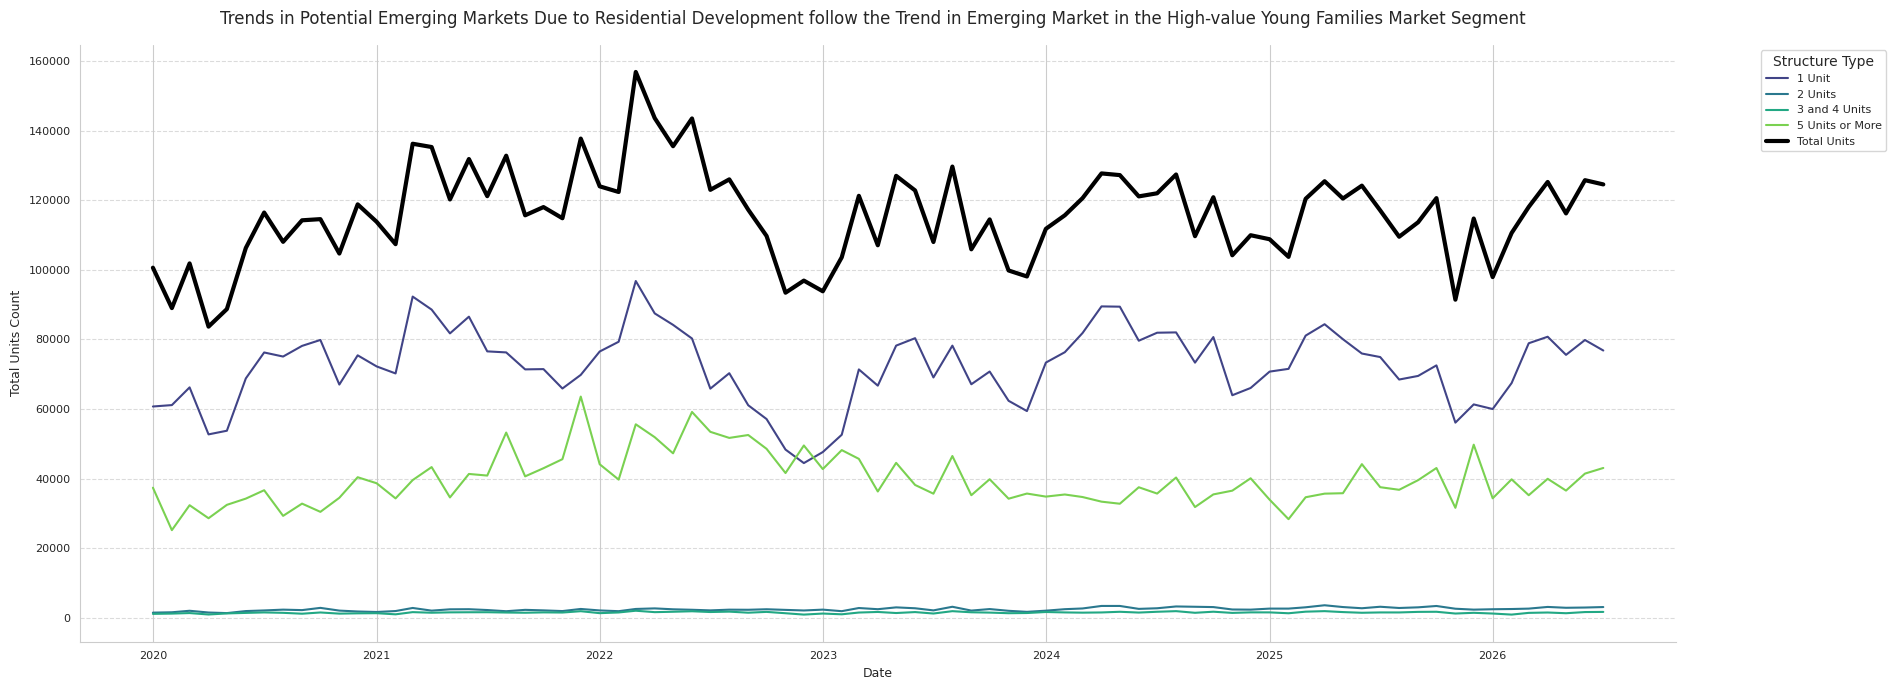

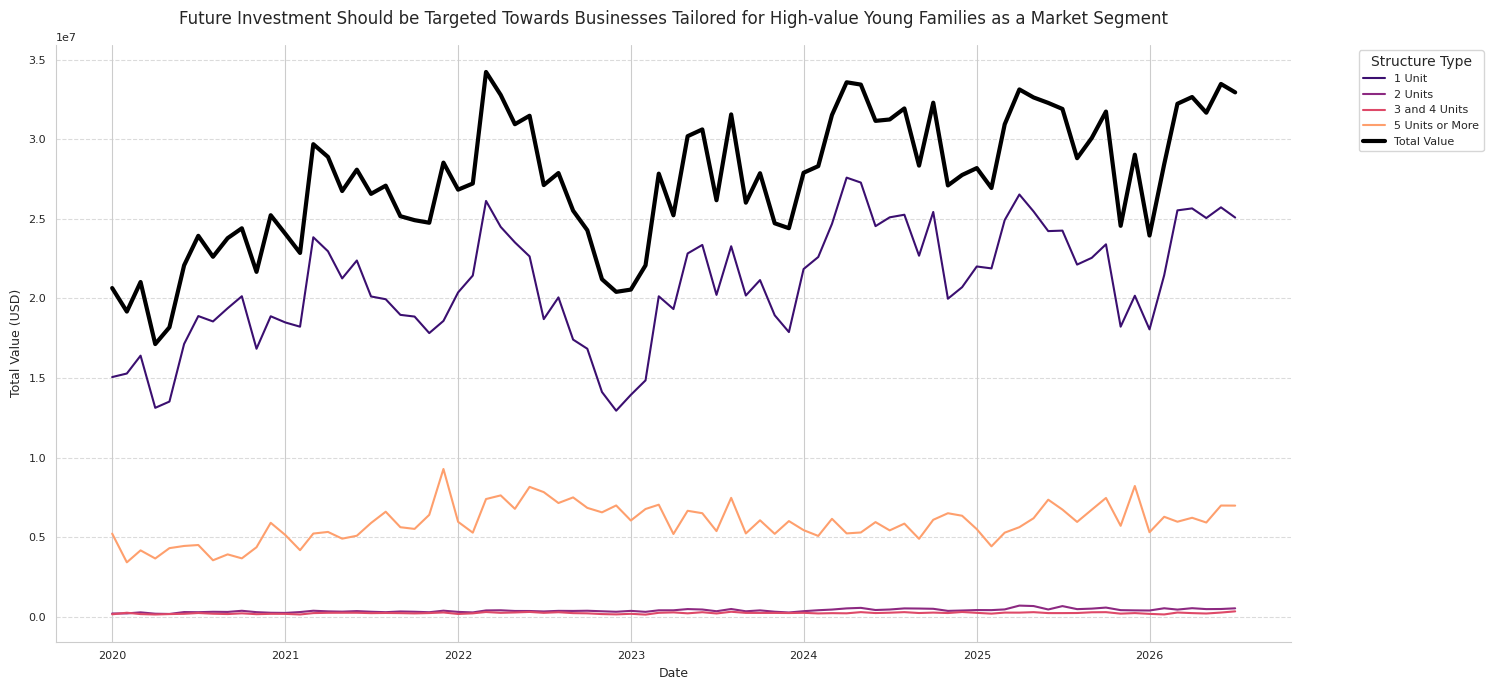

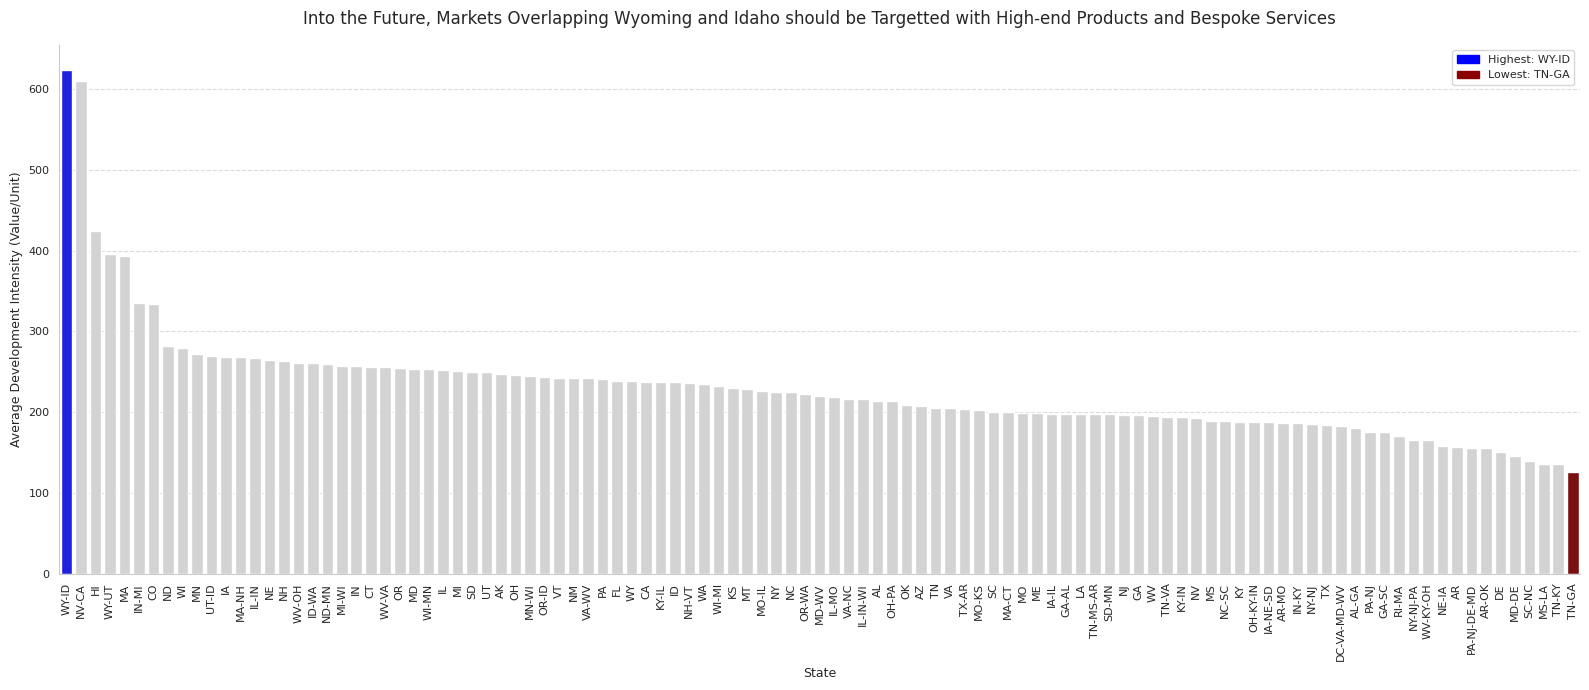

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Converting 'development_intensity' to numeric,
df_merged['development_intensity'] = pd.to_numeric(df_merged['development_intensity'], errors='coerce')

# Setting Plot Style
sns.set_style("whitegrid")

plt.rcParams.update({'font.size': 10})
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['axes.labelsize'] = 9
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['legend.fontsize'] = 8

# Visualization 1: Monthly Units Count Trajectory by Residential Structure Type
# Aggregating data for units count over time by residential structure type
units_trend = df_merged.groupby(['date', 'residential_structure_type'])['units_count'].sum().reset_index()

# Calculate total units count across all structure types
total_units_trend = df_merged.groupby('date')['units_count'].sum().reset_index()

# Plot
plt.figure(figsize=(19, 7))
ax1 = sns.lineplot(data=units_trend, x='date', y='units_count', hue='residential_structure_type', palette='viridis')

# Get existing handles and labels for the legend from sns.lineplot
individual_handles, individual_labels = ax1.get_legend_handles_labels()

# Plot the total trend line
line_total_units, = ax1.plot(total_units_trend['date'], total_units_trend['units_count'], color='black', linewidth=3, label='Total Units')

# Combine individual and total handles/labels for the final legend
final_handles = individual_handles + [line_total_units]
final_labels = individual_labels + ['Total Units']

plt.title('Trends in Potential Emerging Markets Due to Residential Development follow the Trend in Emerging Market in the High-value Young Families Market Segment', pad=15)
plt.xlabel('Date')
plt.ylabel('Total Units Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
ax1.legend(handles=final_handles, labels=final_labels, title='Structure Type', bbox_to_anchor=(1.05, 1), loc='upper left')
ax1.spines['right'].set_visible(False)
ax1.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

# Visualization 2: Monthly Value Trajectory by Residential Structure Type
# Aggregating data for value_usd over time by residential structure type
value_trend = df_merged.groupby(['date', 'residential_structure_type'])['value_usd'].sum().reset_index()

# Calculate total value_usd across all structure types
total_value_trend = df_merged.groupby('date')['value_usd'].sum().reset_index()

# Plot
plt.figure(figsize=(15, 7))
ax2 = sns.lineplot(data=value_trend, x='date', y='value_usd', hue='residential_structure_type', palette='magma')

# Get existing handles and labels for the legend from sns.lineplot
individual_handles, individual_labels = ax2.get_legend_handles_labels()

# Plot the total trend line
line_total_value, = ax2.plot(total_value_trend['date'], total_value_trend['value_usd'], color='black', linewidth=3, label='Total Value')

# Combine individual and total handles/labels for the final legend
final_handles = individual_handles + [line_total_value]
final_labels = individual_labels + ['Total Value']


plt.title('Future Investment Should be Targeted Towards Businesses Tailored for High-value Young Families as a Market Segment', pad=15)
plt.xlabel('Date')
plt.ylabel('Total Value (USD)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
ax2.legend(handles=final_handles, labels=final_labels, title='Structure Type', bbox_to_anchor=(1.05, 1), loc='upper left')
ax2.spines['right'].set_visible(False)
ax2.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

# Visualization 3: Bar chart for Average Development Intensity by State, highlighting highest and lowest
# Calculating the average development intensity per state
state_avg_intensity = df_merged.groupby('State')['development_intensity'].mean().sort_values(ascending=False).reset_index()
# Identifying the state with the highest and lowest average development intensity
highest_state = state_avg_intensity.iloc[0]['State']
lowest_state = state_avg_intensity.iloc[-1]['State']
# Defining colors: highlighting highest and lowest, grey out the rest
def get_color(state):
    if state == highest_state:
        return 'blue'  # Color for highest
    elif state == lowest_state:
        return 'darkred'  # Color for lowest
    else:
        return 'lightgrey'  # Color for others
state_avg_intensity['color'] = state_avg_intensity['State'].apply(get_color)
# Plot
plt.figure(figsize=(16, 7))
ax3 = sns.barplot(x='State', y='development_intensity', data=state_avg_intensity, palette=state_avg_intensity['color'].tolist(), hue=state_avg_intensity['State'], legend=False)
plt.title('Into the Future, Markets Overlapping Wyoming and Idaho should be Targetted with High-end Products and Bespoke Services', pad=15)
plt.xlabel('State')
plt.ylabel('Average Development Intensity (Value/Unit)')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
ax3.spines['right'].set_visible(False)
ax3.spines['top'].set_visible(False)
# Legend
import matplotlib.patches as mpatches
highlight_patch = mpatches.Patch(color='blue', label=f'Highest: {highest_state}')
lowlight_patch = mpatches.Patch(color='darkred', label=f'Lowest: {lowest_state}')
plt.legend(handles=[highlight_patch, lowlight_patch], loc='upper right')

plt.tight_layout()
plt.show()